# Bước 4: Biểu diễn Word Embedding & Trích xuất đặc trưng LSA / LDA

**Mục tiêu:**
1. Kiểm tra thống kê 2 ma trận thưa đầu vào (`BoW` và `TF-IDF`) từ Bước 3.
2. Khảo sát số chiều `n_components` cho **LSA (TruncatedSVD)** thông qua biểu đồ phương sai tích lũy (*Cumulative Explained Variance*) để chọn số chiều tối ưu.
3. Huấn luyện **Word2Vec** và kiểm tra độ tương đồng ngữ nghĩa của từ vựng tiếng Việt sau tách từ.
4. Chạy đối chiếu **LDA (gensim)** để trích xuất top từ khóa từng chủ đề tiềm ẩn.
5. Sinh, lưu và kiểm tra định dạng chuẩn của 3 ma trận đặc trưng qua hàm `load_features()`.

In [1]:
import sys
from pathlib import Path

# Đảm bảo import được thư mục src dù chạy notebook từ thư mục notebooks/
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

from src import config
from src.representation.bow_tfidf import load_corpus, load_matrix, matrix_stats
from src.representation.embedding import build_and_save_embedding
from src.features.lsa import build_and_save_all_features, load_features
from src.features.lda import train_lda, get_lda_top_words
from gensim.models import Word2Vec

# Đọc dữ liệu văn bản và ma trận BoW, TF-IDF đã lưu ở Bước 3
df, docs = load_corpus()
X_bow, vec_bow = load_matrix("bow")
X_tfidf, vec_tfidf = load_matrix("tfidf")

print(f"Tổng số bài viết: {len(df)}")
print("Thống kê BoW:", matrix_stats(X_bow))
print("Thống kê TF-IDF:", matrix_stats(X_tfidf))

Tổng số bài viết: 119
Thống kê BoW: {'so_bai': 119, 'so_tu': 2785, 'nnz': 17581, 'do_thua_%': 94.7}
Thống kê TF-IDF: {'so_bai': 119, 'so_tu': 5060, 'nnz': 23072, 'do_thua_%': 96.17}


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator CountVectorizer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own ri

## 1. Khảo sát số chiều giảm chiều LSA (Explained Variance)
Chạy `TruncatedSVD` với số chiều tăng dần từ 10 đến tối đa `min(120, N_articles - 1)` để quan sát tỷ lệ phương sai thông tin giữ lại và lưu biểu đồ vào `outputs/figures/lsa_explained_variance.png`.

,n_components,BoW_LSA_Variance,TFIDF_LSA_Variance
0,10,0.3638,0.1996
1,20,0.5475,0.3417
2,30,0.6621,0.4475
3,40,0.7453,0.5379
4,50,0.8068,0.6204
5,60,0.8548,0.6978
6,70,0.8939,0.7677
7,80,0.9262,0.8321
8,90,0.9532,0.8905
9,100,0.9746,0.9404


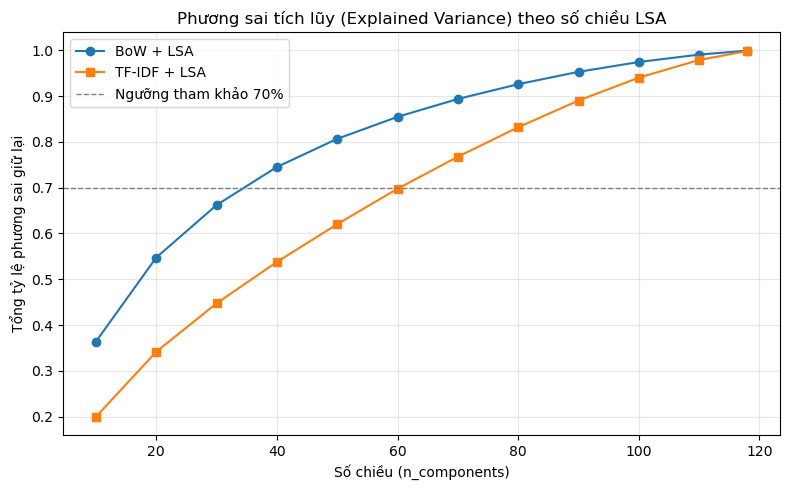

In [2]:
max_k = min(120, X_tfidf.shape[0] - 1, X_tfidf.shape[1] - 1)
k_values = list(range(10, max_k + 1, 10))
if max_k not in k_values:
    k_values.append(max_k)

bow_var, tfidf_var = [], []
for k in k_values:
    svd_b = TruncatedSVD(n_components=k, random_state=config.RANDOM_STATE).fit(X_bow)
    svd_t = TruncatedSVD(n_components=k, random_state=config.RANDOM_STATE).fit(X_tfidf)
    bow_var.append(svd_b.explained_variance_ratio_.sum())
    tfidf_var.append(svd_t.explained_variance_ratio_.sum())

# Bảng đối chiếu nhanh
df_var = pd.DataFrame({
    "n_components": k_values,
    "BoW_LSA_Variance": np.round(bow_var, 4),
    "TFIDF_LSA_Variance": np.round(tfidf_var, 4),
})
display(df_var)

# Vẽ biểu đồ và lưu ra outputs/figures/
fig_dir = ROOT_DIR / "outputs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(k_values, bow_var, marker="o", label="BoW + LSA")
plt.plot(k_values, tfidf_var, marker="s", label="TF-IDF + LSA")
plt.axhline(0.70, color="gray", linestyle="--", linewidth=1, label="Ngưỡng tham khảo 70%")
plt.title("Phương sai tích lũy (Explained Variance) theo số chiều LSA")
plt.xlabel("Số chiều (n_components)")
plt.ylabel("Tổng tỷ lệ phương sai giữ lại")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(fig_dir / "lsa_explained_variance.png", dpi=150)
plt.show()

## 2. Huấn luyện Word2Vec & Kiểm tra chất lượng Embedding
Huấn luyện mô hình Word2Vec (Skip-gram) trên tập từ đã tách (`tokens`) và kiểm tra các từ lân cận về mặt ngữ nghĩa.

In [3]:
emb_stats = build_and_save_embedding(vector_size=config.W2V_SIZE)
print("Thống kê Embedding:", emb_stats)

w2v = Word2Vec.load(str(config.MODELS_DIR / "word2vec.model"))

# Thử kiểm tra một số từ khóa phổ biến có trong từ điển
sample_words = ["bóng_đá", "công_nghệ", "kinh_tế", "bệnh_viện", "apple"]
for word in sample_words:
    if word in w2v.wv:
        sim_words = [f"{w} ({score:.2f})" for w, score in w2v.wv.most_similar(word, topn=5)]
        print(f"- Từ gần nghĩa với '{word}': {', '.join(sim_words)}")

Thống kê Embedding: {'so_bai': 119, 'so_chieu': 80, 'vocab_size': 3406}
- Từ gần nghĩa với 'bóng_đá': thường_niên (0.79), olympic (0.75), quyền_hạn (0.75), cơ_cấu (0.74), suất (0.73)
- Từ gần nghĩa với 'công_nghệ': khoa_học (0.73), lõi (0.71), vắc (0.70), uav (0.70), công_đoạn (0.69)
- Từ gần nghĩa với 'kinh_tế': vĩ_mô (0.73), martin_sommer (0.71), tăng_trưởng (0.68), củng_cố (0.64), nhìn_nhận (0.64)
- Từ gần nghĩa với 'bệnh_viện': đa_khoa (0.85), tân_hưng (0.83), khánh_hội (0.83), chủ_lực (0.82), thực_trạng (0.82)
- Từ gần nghĩa với 'apple': trang_web (0.84), vĩnh_viễn (0.81), dạng (0.81), diễn_đàn (0.81), đóng_cửa (0.80)


## 3. Đối chiếu mô hình chủ đề LDA (Gensim)
Chạy LDA với `num_topics` bằng số chủ đề thực tế trong dữ liệu để lấy danh sách từ khóa đại diện từng chủ đề.

In [4]:
n_true_topics = df["true_label"].nunique()
lda_model, lda_dict, X_lda = train_lda(num_topics=n_true_topics)
top_words = get_lda_top_words(lda_model, topn=10)

print(f"Top 10 từ khóa của {n_true_topics} chủ đề LDA:")
for topic_id, words in top_words.items():
    print(f"  Topic {topic_id}: {', '.join(words)}")

Top 10 từ khóa của 6 chủ đề LDA:
  Topic 0: việt_nam, phim, đội_tuyển, diễn_viên, trận, hlv, nghệ_sĩ, giải, phương_thanh, trận_đấu
  Topic 1: bệnh_viện, bác_sĩ, bệnh, tăng, điều_trị, bệnh_nhân, khám, thuốc, y_tế, người_bệnh
  Topic 2: nvidia, nhà, huang, giá, thuế, đồng, doanh_nghiệp, tiền, tài_chính, đầu_tư
  Topic 3: lực_lượng, gas, lớn, việt_nam, tuổi, nhà, đường, khu_vực, nổ, vụ
  Topic 4: hlv, utd, man, lừa_đảo, dùng, cảnh_báo, đội, man_utd, carrick, clb
  Topic 5: việt_nam, bộ, công_nghệ, microsoft, tỉnh, quản_lý, dữ_liệu, hoạt_động, cơ_sở, tổ_chức


## 4. Sinh toàn bộ ma trận đặc trưng & Kiểm tra quy ước đầu ra (`load_features`)
Chốt số chiều `N_COMPONENTS = 100` (theo biểu đồ Cell 4), lưu 3 ma trận vào `models/` và xác nhận đúng quy ước bàn giao cho Bước 5.

In [5]:
N_COMPONENTS = config.LSA_COMPONENTS  # Tùy kết quả biểu đồ
summary = build_and_save_all_features(n_components=N_COMPONENTS)
print("Kết quả trích xuất đặc trưng:")
print(pd.DataFrame(summary).T)

# Kiểm tra hợp đồng dữ liệu (Data Contract) cho Bước 5
print("\nKiểm tra hàm load_features():")
for feat_name in ["bow_lsa", "tfidf_lsa", "embedding"]:
    X = load_features(feat_name)
    assert isinstance(X, np.ndarray), f"{feat_name} phải là np.ndarray"
    assert X.shape[0] == len(df), f"Số dòng của {feat_name} không khớp articles_clean.csv"
    assert not np.isnan(X).any(), f"{feat_name} chứa giá trị NaN"
    print(f"  [OK] {feat_name:10s} | shape={X.shape} | dtype={X.dtype}")

c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator CountVectorizer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\base.py:318: UserWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.2.2. This might lead to breaking code or invalid results. Use at your own ri

Kết quả trích xuất đặc trưng:
               shape explained_variance_ratio_sum
bow_lsa    [119, 80]                       0.9262
tfidf_lsa  [119, 80]                       0.8321
embedding  [119, 80]                          NaN

Kiểm tra hàm load_features():
  [OK] bow_lsa    | shape=(119, 80) | dtype=float32
  [OK] tfidf_lsa  | shape=(119, 80) | dtype=float32
  [OK] embedding  | shape=(119, 80) | dtype=float32
